In [1]:
# %%
import json
import math
from typing import Any, Dict, Iterable, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Arc, Rectangle, ConnectionPatch, Polygon

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (10, 6)

# ---- file paths: update the match_id file names accordingly ----
MATCHES_CSV   = "matches_df.csv"
LINEUPS_CSV   = "lineups_df.csv"
EVENTS_CSV    = "events_by_match/events_3788741.csv"         # change to your chosen match file
FRAMES360_CSV = "frames_360_by_match/frames_360_3788741.csv"     # same match_id


In [2]:
# %%
matches = pd.read_csv(MATCHES_CSV)
lineups = pd.read_csv(LINEUPS_CSV)
events  = pd.read_csv(EVENTS_CSV)
frames  = pd.read_csv(FRAMES360_CSV)

print("matches:", matches.shape, "| lineups:", lineups.shape, "| events:", events.shape, "| frames:", frames.shape)
print("\nEvents head columns:", list(events.columns[:20]))
print("Frames head columns:", list(frames.columns))


matches: (51, 22) | lineups: (2345, 10) | events: (3803, 115) | frames: (45737, 7)

Events head columns: ['fifty_fifty', 'bad_behaviour_card', 'ball_receipt_outcome', 'ball_recovery_offensive', 'ball_recovery_recovery_failure', 'block_deflection', 'block_offensive', 'block_save_block', 'carry_end_location', 'clearance_aerial_won', 'clearance_body_part', 'clearance_head', 'clearance_left_foot', 'clearance_other', 'clearance_right_foot', 'counterpress', 'dribble_no_touch', 'dribble_nutmeg', 'dribble_outcome', 'dribble_overrun']
Frames head columns: ['id', 'match_id', 'visible_area', 'teammate', 'actor', 'keeper', 'location']


In [3]:
# %%
def try_json(x):
    if pd.isna(x):
        return None
    if isinstance(x, (list, dict)):
        return x
    s = str(x)
    try:
        return json.loads(s)
    except Exception:
        # some CSVs store lists as like "[52.3, 33.2]"
        # or with single quotes — try a fallback
        try:
            return json.loads(s.replace("'", '"'))
        except Exception:
            return None

def parse_point(pt) -> Optional[Tuple[float,float]]:
    if isinstance(pt, (list, tuple)) and len(pt) >= 2:
        return float(pt[0]), float(pt[1])
    return None

def draw_pitch(ax=None, linecolor="black", lw=1):
    if ax is None:
        ax = plt.gca()
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 80)
    ax.set_aspect("equal")
    ax.axis("off")
    # outline & halves
    ax.add_patch(Rectangle((0, 0), 120, 80, fill=False, ec=linecolor, lw=lw))
    ax.plot([60, 60], [0, 80], color=linecolor, lw=lw)
    # boxes
    ax.add_patch(Rectangle((0, 18), 18, 44, fill=False, ec=linecolor, lw=lw))      # left box
    ax.add_patch(Rectangle((102, 18), 18, 44, fill=False, ec=linecolor, lw=lw))     # right box
    # six-yard
    ax.add_patch(Rectangle((0, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    ax.add_patch(Rectangle((114, 30), 6, 20, fill=False, ec=linecolor, lw=lw))
    # penalty spots & arcs
    ax.plot(12, 40, 'o', color=linecolor, ms=2)
    ax.plot(108, 40, 'o', color=linecolor, ms=2)
    ax.add_patch(Arc((12, 40), 20, 20, angle=0, theta1=-90, theta2=90, ec=linecolor, lw=lw))
    ax.add_patch(Arc((108, 40), 20, 20, angle=0, theta1=90, theta2=270, ec=linecolor, lw=lw))
    # center circle
    ax.add_patch(Arc((60, 40), 20, 20, angle=0, theta1=0, theta2=360, ec=linecolor, lw=lw))
    return ax


In [4]:
# %%
shots = events[events["type"] == "Shot"].copy()
shots["xy"] = shots["location"].apply(try_json).apply(parse_point)
shots["end_xy"] = shots["shot_end_location"].apply(try_json).apply(parse_point) if "shot_end_location" in shots.columns else None

shots["x"] = shots["xy"].apply(lambda p: p[0] if p else np.nan)
shots["y"] = shots["xy"].apply(lambda p: p[1] if p else np.nan)
if "shot_statsbomb_xg" in shots.columns:
    shots["xg"] = pd.to_numeric(shots["shot_statsbomb_xg"], errors="coerce")
else:
    shots["xg"] = np.nan



In [5]:
# Find all shots with xG >= 0.08
shots_high_xg = shots[shots["xg"] >= 0.08].copy()

# Get unique possession numbers for these shots
high_xg_possessions = shots_high_xg["possession"].unique()

# For each possession, retrieve all events in the possession leading up to the shot
possessions_events = {}
for pos_num in high_xg_possessions:
    # All events with this possession number, ordered by event index/id if available
    # (Assumption: "index" or "event_id" or row index gives chronological order, else fallback to DataFrame order)
    possession_events = events[events["possession"] == pos_num]
    # Optional: sort if you have a 'minute', 'second', or 'index' column
    if "index" in possession_events.columns:
        possession_events = possession_events.sort_values("index")
    elif "event_id" in possession_events.columns:
        possession_events = possession_events.sort_values("event_id")
    possessions_events[pos_num] = possession_events

# # Optionally: print summaries for each possession
# for pos_num, evdf in possessions_events.items():
#     print(f"\n--- Possession {pos_num} ---")
#     print(evdf[["minute", "second", "team", "type", "player", "x", "y", "outcome", "xg"]]
#           if all(c in evdf.columns for c in ["minute", "second", "team", "type", "player", "x", "y", "outcome", "xg"])
#           else evdf.head(10))

/var/folders/vw/z2xv57_n70l_szw_fr80j5km0000gn/T/ipykernel_83443/84923289.py:534: UserWarning: Glyph 128683 (\N{NO ENTRY SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/Users/finneganlaister-smith/Library/Python/3.12/lib/python/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 128683 (\N{NO ENTRY SIGN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


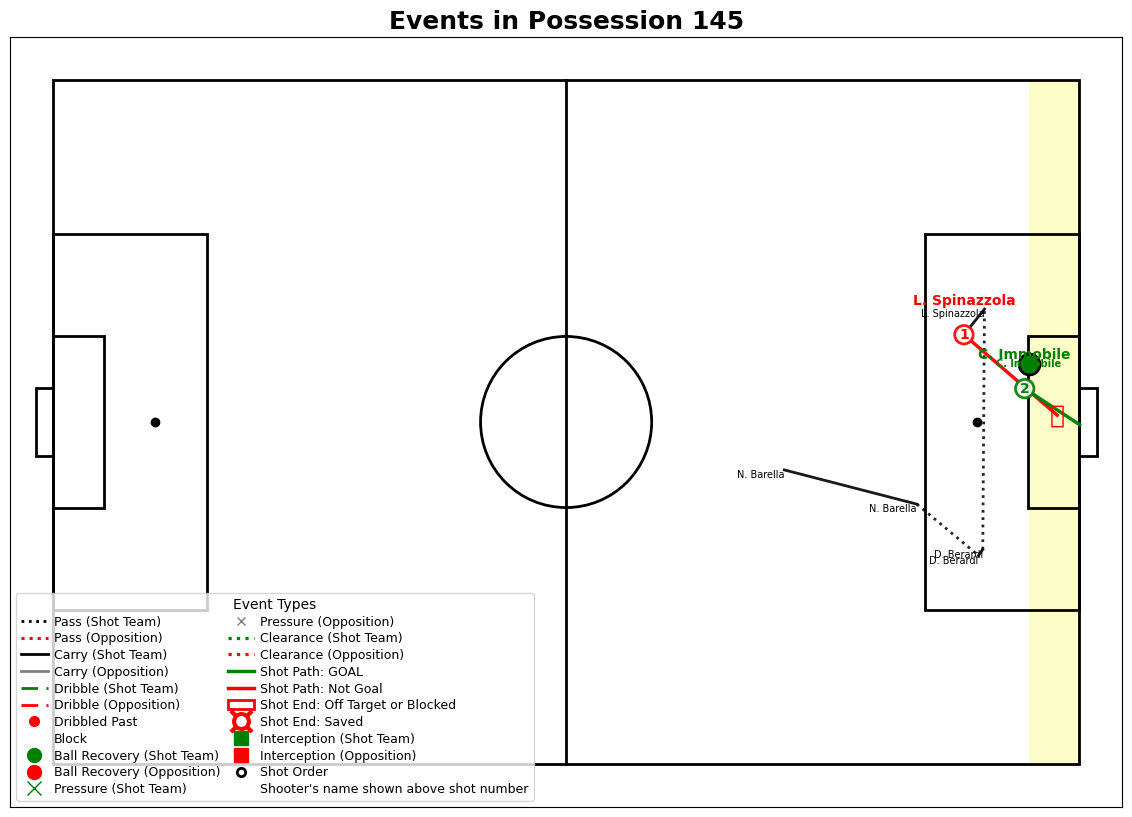

In [7]:
number_of_interest = 3


# Only look at events for a single possession at a time
# Pick a possession number to examine (choose from one in 'high_xg_possessions', e.g., high_xg_possessions[0])
single_possession_num = high_xg_possessions[number_of_interest]  # Or change to any possession number you are interested in

df = possessions_events[single_possession_num]

# Reorder columns for easier reading
cols_first = [
    "type", "minute", "timestamp", "second", "location", "play_pattern", "player", "position", "shot_statsbomb_xg",
    "possession", "possession_team", "pass_angle", "pass_end_location", "pass_height", "pass_length",
    "pass_recipient", "pass_technique", "team", "period", 
]
# Remove duplicates if present
cols_first = [c for i, c in enumerate(cols_first) if c not in cols_first[:i]]

def reorder_cols(df, cols_first):
    all_cols = df.columns.tolist()
    first = [c for c in cols_first if c in all_cols]
    rest = [c for c in all_cols if c not in first]
    return df[first + rest]

reordered_df = reorder_cols(df, cols_first)
# Add a "source_possession" column for clarity (optional)
reordered_df = reordered_df.copy()
reordered_df["source_possession"] = single_possession_num

reordered_df = reordered_df.sort_values("timestamp")


# Find the 'Shot' event in reordered_df
shot_row = reordered_df[(reordered_df['type'] == 'Shot') & (reordered_df['shot_statsbomb_xg'] >= 0.08)]
if not shot_row.empty:
    # Get the minute and second of the shot event (take first if multiple)
    shot_minute = shot_row.iloc[0]['minute']
    shot_second = shot_row.iloc[0]['second']
    # Convert to absolute time in seconds
    shot_abs_time = shot_minute * 60 + shot_second
    # Add absolute time to the dataframe for filtering
    reordered_df = reordered_df.copy()
    reordered_df['abs_time'] = reordered_df['minute'] * 60 + reordered_df['second']
    # Take only events in the 10 seconds preceding (inclusive of the 'Shot' event)
    reordered_df_special = reordered_df[
        (reordered_df['abs_time'] >= shot_abs_time - 10) &
        (reordered_df['abs_time'] <= shot_abs_time)
    ]
    # Optionally, drop the helper column
    reordered_df_special = reordered_df_special.drop(columns=['abs_time'])
else:
    # If no Shot, just return empty or all
    reordered_df_special = reordered_df.iloc[0:0]

# reordered_df_special['type'].value_counts()


# Add a new column "High Turnover?" for each row: True if this event is a Ball Recovery or Interception, by the shot team, in the opponent's half
import numpy as np
import ast

# Determine the team that took the shot (if there is a shot in the window)
if 'type' in reordered_df_special.columns and not reordered_df_special[reordered_df_special["type"] == 'Shot'].empty:
    shot_team = reordered_df_special.loc[reordered_df_special["type"] == 'Shot', 'team'].iloc[0]
else:
    shot_team = np.nan

high_turnover_list = []

if not reordered_df_special.empty:
    reordered_df_special = reordered_df_special.copy()
    for idx, row in reordered_df_special.iterrows():
        is_high = False
        # Check if event is Ball Recovery or Interception
        if row.get('type', None) in ('Ball Recovery', 'Interception'):
            loc = row.get('location', None)
            # Handle if stored as string, e.g., '[86.7, 56.3]'
            if isinstance(loc, str):
                try:
                    loc_eval = ast.literal_eval(loc)
                    if isinstance(loc_eval, (list, tuple)):
                        loc = loc_eval
                except Exception:
                    loc = None
            # Must have location as [x, y] (or tuple)
            if isinstance(loc, (list, tuple)) and len(loc) == 2:
                # Check if it's by the shot team
                if 'team' in row and row['team'] == shot_team:
                    # Opponent's half (x > 60 in StatsBomb coords)
                    if float(loc[0]) > 60:
                        is_high = True
        high_turnover_list.append(is_high)
    reordered_df_special['High Turnover?'] = high_turnover_list
else:
    reordered_df_special['High Turnover?'] = []




import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_pitch(ax=None, color='black', lw=2):
    # Create a pitch 120 x 80 (standard StatsBomb coords)
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 8))
    # Outline & center line
    ax.add_patch(patches.Rectangle((0, 0), 120, 80, fill=False, edgecolor=color, lw=lw))
    ax.plot([60, 60], [0, 80], color=color, lw=lw)
    # Left penalty box
    ax.add_patch(patches.Rectangle((0, 18), 18, 44, fill=False, edgecolor=color, lw=lw))
    # Right penalty box
    ax.add_patch(patches.Rectangle((102, 18), 18, 44, fill=False, edgecolor=color, lw=lw))
    # Left 6-yard box
    ax.add_patch(patches.Rectangle((0, 30), 6, 20, fill=False, edgecolor=color, lw=lw))
    # Right 6-yard box
    ax.add_patch(patches.Rectangle((114, 30), 6, 20, fill=False, edgecolor=color, lw=lw))
    # Center circle
    cc = plt.Circle((60, 40), 10, color=color, fill=False, lw=lw)
    ax.add_patch(cc)
    # Penalty spots
    ax.plot(12, 80-40, marker='o', color=color)
    ax.plot(108, 80-40, marker='o', color=color)
    # Goals
    ax.add_patch(patches.Rectangle((-2, 80-36-8), 2, 8, fill=False, edgecolor=color, lw=lw))
    ax.add_patch(patches.Rectangle((120, 80-36-8), 2, 8, fill=False, edgecolor=color, lw=lw))
    ax.set_xlim(-5, 125)
    ax.set_ylim(-5, 85)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal')
    return ax

def get_xy(loc_field):
    """Handle if location is a list or string, otherwise returns (nan, nan)."""
    import numpy as np
    if isinstance(loc_field, (list, tuple)) and len(loc_field) >= 2:
        return float(loc_field[0]), float(loc_field[1])
    elif isinstance(loc_field, str):
        try:
            arr = eval(loc_field)
            if isinstance(arr, (list, tuple)) and len(arr) >= 2:
                return float(arr[0]), float(arr[1])
        except:
            pass
    return (np.nan, np.nan)

def flip_y(y):
    if y is None:
        return None
    import numpy as np
    if np.isnan(y):
        return y
    return 80 - y

def flip_x(x):
    if x is None:
        return None
    import numpy as np
    if np.isnan(x):
        return x
    return 120 - x

def team_is_shot_team(event_row, shot_team):
    return (event_row.get('team', None) == shot_team)

def plot_squiggly(ax, x1, y1, x2, y2, color='gray', lw=2, zorder=3):
    import numpy as np
    t = np.linspace(0, 1, 100)
    dx = x2 - x1
    dy = y2 - y1
    length = np.sqrt(dx*dx + dy*dy)
    if length < 1e-2:
        return
    ortho_x = -dy / length
    ortho_y = dx / length
    A = min(2, 0.12 * length)
    freq = 10
    squiggle = A * np.sin(2 * np.pi * freq * t)
    x = x1 + dx * t + squiggle * ortho_x
    y = y1 + dy * t + squiggle * ortho_y
    ax.plot(x, y, color=color, linewidth=lw, alpha=0.75, zorder=zorder)

def format_player_name(full_name):
    """Format as 'F. Last' given a string like 'Firstname Lastname'."""
    if not isinstance(full_name, str) or len(full_name.strip()) == 0:
        return ""
    parts = full_name.split()
    if len(parts) == 1:
        return parts[0]
    first = parts[0]
    last = parts[-1]
    return f"{first[0]}. {last}"

# --- START NEW LOGIC for High Turnover yellow background ---
import numpy as np

# Scan for all True "High Turnover?" events and collect their x-coordinates
ht_x_thresholds = []
if 'High Turnover?' in reordered_df_special.columns:
    for _, row in reordered_df_special.iterrows():
        if row.get("High Turnover?", False):
            x, y = get_xy(row.get("location"))
            if not np.isnan(x):
                ht_x_thresholds.append(x)
# Only keep unique, sorted threshold values for visual clarity
ht_x_thresholds = sorted(set(ht_x_thresholds))

# Get team of shot event (for conditional coloring)
shot_team = None
shot_row = reordered_df_special[reordered_df_special['type'] == 'Shot']
if not shot_row.empty and ('team' in shot_row.columns):
    shot_team = shot_row.iloc[0]['team']

fig, ax = plt.subplots(figsize=(12,8))
# Paint yellow background if there are relevant high turnover regions
for xthresh in ht_x_thresholds:
    # Draw rectangle from x=xthresh to 120 (end), y=0 to 80 across full height of pitch
    ax.add_patch(
        patches.Rectangle(
            (xthresh, 0),           # (x,y) corner
            120 - xthresh, 80,      # width, height
            facecolor='#fdfdbb',    # light yellow
            edgecolor='none',
            zorder=0,               # Beneath all pitch/elements
            alpha=0.78 if len(ht_x_thresholds)==1 else 0.55   # opaque if single, slightly lighter if >1 regions
        )
    )
# Draw pitch lines etc. on top of yellow
draw_pitch(ax=ax)

# --- NEW: enumerate all shots and keep their order for annotation
shots = reordered_df_special[reordered_df_special['type'] == 'Shot'].sort_values(['minute','second','timestamp'] if 'timestamp' in reordered_df_special.columns else ['minute','second'])
shot_indices = list(shots.index)
shot_numbers = {idx: num+1 for num, idx in enumerate(shot_indices)}  # map row idx to "1", "2", ...
shot_player_names = {idx: shots.loc[idx].get('player', '') for idx in shot_indices}  # map row idx to player

for i, event in reordered_df_special.iterrows():
    typ = event.get('type', None)
    if pd.isna(typ): continue
    player = event.get('player', None)
    player_short = format_player_name(player)

    ###### Passes done by the opposition (not the shot team) #######
    if typ == "Pass" and not team_is_shot_team(event, shot_team):
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('pass_end_location'))

        # Flip BOTH start and end X and Y for opposition passes
        start_x_flipped = flip_x(start_x)
        end_x_flipped = flip_x(end_x)
        start_y_flipped = flip_y(start_y)
        end_y_flipped = end_y # unchanged as before

        if not (np.isnan(start_x_flipped) or np.isnan(end_x_flipped)):
            # Red dotted line for passes by the opposition
            ax.plot([start_x_flipped, end_x_flipped], [start_y_flipped, end_y_flipped],
                    color='red', linestyle=':', lw=2.2, alpha=0.92, zorder=13)
            # Annotate at start location
            if player_short:
                ax.text(start_x_flipped, start_y_flipped, player_short, fontsize=7,
                        color='red', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    # Passes by shot team (keep as before: black dotted line, flip_y on Y only)
    if typ == "Pass":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('pass_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle=':', lw=2, alpha=0.85, zorder=2)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='black', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    ###### Carry: black solid line for shot team, grey solid line for opposition ######
    if typ == "Carry":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('carry_end_location'))

        if team_is_shot_team(event, shot_team):
            # By shot team: flip y, black line
            start_y_flipped = flip_y(start_y)
            end_y_flipped = flip_y(end_y)
            if not (np.isnan(start_x) or np.isnan(end_x)):
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='black', linestyle='-', lw=2, alpha=0.9, zorder=3)
                if player_short:
                    ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='black', verticalalignment='top', horizontalalignment='right', zorder=40)
        else:
            # By opposition: grey (not red!), no flip, flip BOTH start and end X for opposition carries, don't flip Y at all
            start_x_flipped = flip_x(start_x)
            end_x_flipped = flip_x(end_x)
            if not (np.isnan(start_x_flipped) or np.isnan(end_x_flipped)):
                ax.plot([start_x_flipped, end_x_flipped], [start_y, end_y], color='gray', linestyle='-', lw=2, alpha=0.9, zorder=3)
                if player_short:
                    ax.text(start_x_flipped, start_y, player_short, fontsize=7, color='gray', verticalalignment='top', horizontalalignment='right', zorder=40)
        continue

    ###### Dribble - green squiggly line for shot team, red squiggly line for opposition ######
    if typ == "Dribble":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('dribble_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if team_is_shot_team(event, shot_team):
            line_color = 'green'
            label_color = 'green'
        else:
            line_color = 'red'
            label_color = 'red'
        if (not np.isnan(start_x)) and (not np.isnan(end_x)):
            plot_squiggly(ax, start_x, start_y_flipped, end_x, end_y_flipped, color=line_color, lw=2, zorder=4)
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color=label_color, verticalalignment='top', horizontalalignment='left', zorder=40)
        continue

    ###### Dribbled Past - small red circle ######
    if typ == "Dribbled Past":
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        if not np.isnan(x):
            ax.plot(x_flipped, y, marker='o', color='red', markersize=7, markeredgewidth=1.7, zorder=9)
            if player_short:
                ax.text(x_flipped, y, player_short, fontsize=7, color='red', verticalalignment='bottom', horizontalalignment='left', zorder=40)
        continue

    ###### Blocks by the opposition (not shot team) -- text "BLOCK" in red, small ######
    if typ == "Block" and not team_is_shot_team(event, shot_team):
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        y_flipped = y  # No flipping for y for marker as before
        if not np.isnan(x_flipped):
            # Show small red "BLOCK", rotated 90 degrees counterclockwise
            ax.text(x_flipped, y_flipped, "BLOCK", fontsize=8, ha='center', va='center', color='red', fontweight='bold', zorder=8, rotation=90)
            if player_short:
                x_text = flip_x(x)
                y_text = y
                ax.text(x_text, y_text, player_short, fontsize=7, color='red',
                        verticalalignment='center', horizontalalignment='left', zorder=40)
        continue

    ###### Blocks by shot team (same team as shot) -- text "BLOCK" in red, small ######
    if typ == "Block" and team_is_shot_team(event, shot_team):
        x, y = get_xy(event.get('location'))
        x_flipped = flip_x(x)
        y_flipped = flip_y(y)
        if not np.isnan(x_flipped):
            # Show small red "BLOCK", rotated 90 degrees counterclockwise
            ax.text(x_flipped, y_flipped, "BLOCK", fontsize=8, ha='center', va='center', color='red', fontweight='bold', zorder=8, rotation=90)
            if player_short:
                ax.text(x_flipped, y_flipped, player_short, fontsize=7, color='red', verticalalignment='center', horizontalalignment='left', zorder=40)
        continue

    ###### Ball Recovery: colored dot by team (shot team: green, else red) ######
    if typ == "Ball Recovery":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            if team_is_shot_team(event, shot_team):
                ax.plot(x, y_flipped, marker='o', color='green', markersize=15, markeredgewidth=2, markeredgecolor='black', zorder=6)
                txt_color = 'green'
            else:
                ax.plot(x, y_flipped, marker='o', color='red', markersize=15, markeredgewidth=2, markeredgecolor='black', zorder=6)
                txt_color = 'red'
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color=txt_color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='semibold')
        continue

    ###### Pressure: X, green if shot team, gray if other. For opposition, flip Y for marker and for text ######
    if typ == "Pressure":
        x, y = get_xy(event.get('location'))
        if team_is_shot_team(event, shot_team):
            y_flipped = flip_y(y)
            if not np.isnan(x):
                ax.plot(x, y_flipped, marker='x', color='green', markersize=15, markeredgewidth=3, zorder=6)
                txt_color = 'green'
                if player_short:
                    ax.text(x, y_flipped, player_short, fontsize=7, color='green', verticalalignment='top', horizontalalignment='center', zorder=40)
        else:
            # Draw opposition "Pressure" names only (gray, NO x marker)
            x_flipped = flip_x(x)
            y_flipped = y  # original Y (do not flip for opp)
            if not np.isnan(x_flipped):
                # ax.plot(x_flipped, y_flipped, marker='x', color='gray', markersize=11, markeredgewidth=2, zorder=6)  # <-- SMALLER gray X (commented out; show NO X)
                if player_short:
                    ax.text(x_flipped, y_flipped, player_short, fontsize=7, color='gray',
                            verticalalignment='top', horizontalalignment='center', zorder=40)
        continue

    ###### Clearance: by shot team = green dotted line, else red dotted line ######
    if typ == "Clearance":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('clearance_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        if not (np.isnan(start_x) or np.isnan(end_x)):
            if team_is_shot_team(event, shot_team):
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='green', linestyle=':', lw=2.3, alpha=0.96, zorder=7)
                txt_color = 'green'
            else:
                ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped], color='red', linestyle=':', lw=2.3, alpha=0.96, zorder=7)
                txt_color = 'red'
            if player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color=txt_color, verticalalignment='bottom', horizontalalignment='right', zorder=40)
        continue

    ###### Shot: LINE COLOR red or green and annotate shot number AND the shooter name ######
    if typ == "Shot":
        start_x, start_y = get_xy(event.get('location'))
        end_x, end_y = get_xy(event.get('shot_end_location'))
        start_y_flipped = flip_y(start_y)
        end_y_flipped = flip_y(end_y)
        outcome = event.get('shot_outcome', '').lower() if event.get('shot_outcome') is not None else ""

        # Color: green if goal, else red
        if outcome == "goal":
            line_color = "green"
        else:
            line_color = "red"

        if not (np.isnan(start_x) or np.isnan(end_x)):
            ax.plot([start_x, end_x], [start_y_flipped, end_y_flipped],
                    color=line_color, linestyle='-', lw=2.5, alpha=0.95, zorder=10)

            # Shot outcome visuals at (end_x, end_y_flipped)
            if outcome == 'off target':
                circ = plt.Circle((end_x, end_y_flipped), 2.7, fill=False, edgecolor='red', lw=2.5, zorder=15)
                ax.add_patch(circ)
            elif outcome == 'saved':
                # Replace red X with 🚫 unicode character (at similar location)
                ax.text(end_x, end_y_flipped, "🚫", fontsize=18, ha='center', va='center', color='red', zorder=15)

            # Number for shot order on the start point
            shot_num = shot_numbers.get(i)
            shot_player = shot_player_names.get(i, player)
            shot_player_short = format_player_name(shot_player)
            if shot_num is not None:
                # Draw shot number SMALLER than before (was fontsize=14), now 10
                ax.text(start_x, start_y_flipped, f"{shot_num}", fontsize=10, color=line_color, fontweight='bold',
                        verticalalignment='center', horizontalalignment='center', zorder=50, bbox=dict(boxstyle="circle,pad=0.16", fc="white", ec=line_color, lw=2, alpha=0.9))
                # Draw shooter's name just below the marker (or above if you'd like)
                if shot_player_short:
                    # Offset a little vertically to avoid collision with number circle
                    ax.text(start_x, start_y_flipped + 3.2, shot_player_short, fontsize=10, color=line_color, fontweight='bold',
                            verticalalignment='bottom', horizontalalignment='center', zorder=51)
            elif player_short:
                ax.text(start_x, start_y_flipped, player_short, fontsize=7, color='red', verticalalignment='bottom', horizontalalignment='center', zorder=40, fontweight='bold')
        continue

    ###### Interception: colored square by team (shot team: green, else red) ######
    if typ == "Interception":
        x, y = get_xy(event.get('location'))
        y_flipped = flip_y(y)
        if not np.isnan(x):
            color = 'green' if team_is_shot_team(event, shot_team) else 'red'
            ax.plot(x, y_flipped, marker='s', color=color, markersize=16, markeredgecolor='black', markeredgewidth=2, zorder=7)
            if player_short:
                ax.text(x, y_flipped, player_short, fontsize=7, color=color, verticalalignment='center', horizontalalignment='center', zorder=40, fontweight='bold' if color=='green' else 'normal')
        continue

    ###### Ball Receipt*: do nothing ######
    if typ == "Ball Receipt*":
        continue

import matplotlib.lines as mlines
import matplotlib.patches as mpatches

# Legend edits:
legend_elements = [
    # Passes
    mlines.Line2D([], [], color='black', linestyle=':', lw=2, label='Pass (Shot Team)'),
    mlines.Line2D([], [], color='red', linestyle=':', lw=2.2, label='Pass (Opposition)'),

    # Carries
    mlines.Line2D([], [], color='black', linestyle='-', lw=2, label='Carry (Shot Team)'),
    mlines.Line2D([], [], color='gray', linestyle='-', lw=2, label='Carry (Opposition)'),

    # Dribble - shot team green squiggly, not shot team red squiggly
    mlines.Line2D([], [], color='green', lw=2, linestyle=(0, (6,3,2,3)), label='Dribble (Shot Team)'),    # custom squiggly
    mlines.Line2D([], [], color='red', lw=2, linestyle=(0, (6,3,2,3)), label='Dribble (Opposition)'),     # custom squiggly

    # Dribbled Past
    mlines.Line2D([], [], color='red', marker='o', markersize=7, lw=0, label='Dribbled Past'),  # changed to small red circle

    # Blocks - now "BLOCK" in red, small, no marker
    mlines.Line2D([], [], color='red', marker='', lw=0, label='Block', linestyle='None'),

    # Ball Recovery
    mlines.Line2D([], [], color='green', marker='o', markersize=10, lw=0, label='Ball Recovery (Shot Team)'),
    mlines.Line2D([], [], color='red', marker='o', markersize=10, lw=0, label='Ball Recovery (Opposition)'),

    # Pressure
    mlines.Line2D([], [], color='green', marker='x', markersize=10, lw=0, label='Pressure (Shot Team)'),
    mlines.Line2D([], [], color='gray', marker='x', markersize=6, lw=0, label='Pressure (Opposition)'), # smaller opp pressure

    # Clearance
    mlines.Line2D([], [], color='green', linestyle=':', lw=2.3, label='Clearance (Shot Team)'),
    mlines.Line2D([], [], color='red', linestyle=':', lw=2.3, label='Clearance (Opposition)'),

    # Shots - outcome dependent
    mlines.Line2D([], [], color='green', linestyle='-', lw=2.5, label='Shot Path: GOAL'),
    mlines.Line2D([], [], color='red', linestyle='-', lw=2.5, label='Shot Path: Not Goal'),
    mpatches.Patch(facecolor='none', edgecolor='red', linewidth=2, label='Shot End: Off Target or Blocked', alpha=1),
    mlines.Line2D([], [], color='red', marker='$🚫$', markersize=16, lw=0, label='Shot End: Saved'),  # now shows 'no' emoji in legend
    # No more green arrow in legend

    # Interception
    mlines.Line2D([], [], color='green', marker='s', markersize=10, lw=0, label='Interception (Shot Team)'),
    mlines.Line2D([], [], color='red', marker='s', markersize=10, lw=0, label='Interception (Opposition)'),

    # Shot Number
    mlines.Line2D([], [], marker='o', color='w', markerfacecolor='w', markeredgecolor='black', markeredgewidth=2, lw=0, label='Shot Order'),
    mlines.Line2D([], [], marker=None, color='w', lw=0, label="Shooter's name shown above shot number")
]

# Add legend to plot
# Remove whitespace: set columnspacing, handletextpad, and borderpad small
legend = ax.legend(
    handles=legend_elements,
    loc='lower left',
    fontsize=9,
    frameon=True,
    ncol=2,
    title='Event Types',
    borderaxespad=0.5,   # tight border to axes
    columnspacing=0.6,   # reduce horizontal padding between columns
    handletextpad=0.5,   # reduce space between handle and text
    labelspacing=0.3,    # reduce vertical space between entries
    borderpad=0.4,       # padding inside the legend border
    handlelength=2.1     # make handles a little longer if desired
)
# "tight_layout" also helps a bit for squeeze in notebook
plt.tight_layout()
ax.set_title(f"Events in Possession {single_possession_num}", fontsize=18, fontweight='bold')

plt.show()
